# 첫 스크립트와 디버거

**이 노트북에서 할 일**

1. 실습 폴더의 `hello.py`와 같은 네 줄을 파일로 저장하고 실행해, 출력을 예상과 비교합니다.
2. 곱셈 기호 하나를 덧셈으로 바꾼 스크립트가 오류 없이 틀린 합계를 내는 것을 봅니다.
3. 디버거로 3번 줄 앞에서 멈춰 값을 보고, 기호를 고친 뒤 같은 명령으로 다시 확인합니다.

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 노트북이 임시 폴더에 스크립트를 직접 만듭니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

커널은 3절에서 준비한 실습 폴더의 `.venv`를 고릅니다. VS Code 화면에서 디버거를 쓰는 방법은 교재 본문에 있습니다.

## 오늘 볼 그림

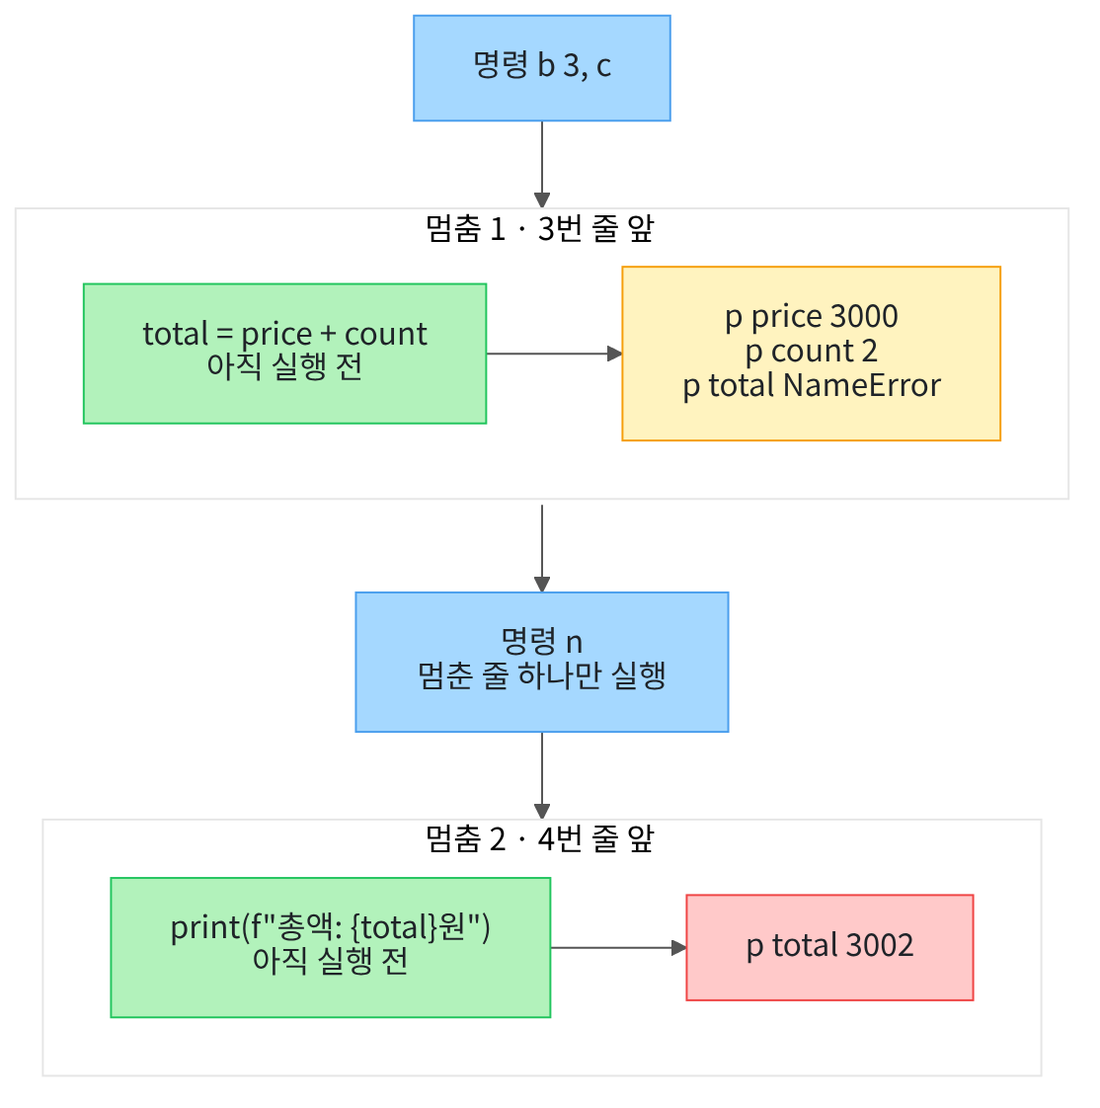

위에서 아래로 읽습니다. 파란 상자는 디버거에 넣은 명령이고, 초록 상자는 멈춘 줄(아직 실행 전)입니다.
노란 상자는 값을 확인한 결과이고, 빨간 상자는 틀린 합계 `3002`입니다.
멈춘 줄은 아직 실행 전이라서 한 줄 실행 명령 `n` 뒤에야 `total`이 생깁니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 3절에서 쓴 기본 기능 네 가지를 다시 불러옵니다.
모듈 `subprocess`는 노트북 안에서 다른 프로그램을 실행하고, 모듈 `sys`는 실행 중인 Python의 정보를 알려 줍니다.
모듈 `tempfile`과 경로 기능 `Path`는 2절처럼 임시 폴더와 경로를 다룹니다.

In [1]:
# 이 절에서 쓰는 Python 기본 기능을 불러옵니다
import subprocess
import sys
import tempfile
from pathlib import Path

print("불러오기 완료")

불러오기 완료


**결과 읽기** — `불러오기 완료`가 보이면 다음 셀로 넘어갑니다.

## 2. 연습용 폴더와 파일 이름 정하기

2절·3절처럼 내 문서를 건드리지 않도록 임시 폴더 `workspace`에서 연습합니다.

이 노트북은 스크립트 파일 네 개를 씁니다. 이번 셀은 먼저 세 개의 경로를 정합니다.
바른 계산 `hello.py`, 틀린 계산 `price_bug.py`, 고친 계산 `price_fixed.py`입니다.
값 바꿔 보기의 `price_changed.py`는 그 셀에서 정합니다. 경로만 정하므로 파일은 아직 없습니다.

In [2]:
# 연습용 임시 폴더를 만들고, 스크립트 파일 세 개의 경로를 정합니다
temporary_folder = tempfile.TemporaryDirectory()
workspace = Path(temporary_folder.name)
hello_file = workspace / "hello.py"
bug_file = workspace / "price_bug.py"
fixed_file = workspace / "price_fixed.py"
# 경로만 정했으므로 세 파일 모두 아직 없습니다
print("hello.py가 있는가:", hello_file.is_file())
print("price_bug.py가 있는가:", bug_file.is_file())
print("price_fixed.py가 있는가:", fixed_file.is_file())

hello.py가 있는가: False
price_bug.py가 있는가: False
price_fixed.py가 있는가: False


**결과 읽기** — 세 줄 모두 `False`입니다. 아직 파일을 저장하지 않았습니다.

## 3. 스크립트 파일 저장하기

스크립트(script)는 Python 코드를 순서대로 적어 저장한 파일입니다. 실습 폴더의 `hello.py`에는 네 줄이 있습니다.
여러 줄 글은 큰따옴표 세 개 `"""`로 시작하고 끝냅니다. 그 사이의 줄바꿈도 글에 그대로 들어갑니다.

마지막 줄의 `f"총액: {total}원"`은 글 속 중괄호 자리에 `total` 값을 넣습니다.
메서드 `write_text()`는 2절에서 글을 파일에 저장할 때 썼습니다.

In [3]:
# 실습 폴더의 hello.py와 같은 네 줄을 글로 적어 파일에 저장합니다
hello_source = """price = 3000
count = 2
total = price * count
print(f"총액: {total}원")
"""
hello_file.write_text(hello_source, encoding="utf-8")
# splitlines()로 줄을 나눠 코드가 몇 줄인지 셉니다
hello_lines = hello_source.splitlines()
print("hello.py가 있는가:", hello_file.is_file())
print("코드 줄 수:", len(hello_lines))
print("3번 줄:", hello_lines[2])

hello.py가 있는가: True
코드 줄 수: 4
3번 줄: total = price * count


**결과 읽기** — 파일이 있는지는 `True`, 코드 줄 수는 `4`입니다.
3번 줄은 `total = price * count`입니다. 뒤에서 디버거를 멈출 줄이 이 3번 줄입니다.

목록 번호는 0부터 세므로 `[2]`가 세 번째 줄입니다.

## 4. 스크립트 실행하기

터미널에서는 실습 폴더에서 `uv run python hello.py`로 실행합니다. 노트북에서는 3절처럼 커널의 Python으로 실행합니다.
값 `sys.executable`은 이 노트북을 실행하는 Python이고, 함수 `subprocess.run()`에 명령 목록을 넣어 실행합니다.

출력 글 끝에는 줄바꿈이 붙어 있습니다. 메서드 `strip()`은 글 앞뒤의 줄바꿈과 빈칸을 떼어 낸 글을 반환합니다.

In [4]:
# 노트북을 실행하는 Python으로 hello.py를 실행하고 출력을 담습니다
hello_command = [sys.executable, hello_file]
hello_run = subprocess.run(hello_command, capture_output=True, text=True, check=True)
# 출력 끝의 줄바꿈을 떼어 낸 글만 남깁니다
hello_output = hello_run.stdout.strip()
print("스크립트 출력:", hello_output)
print("종료 코드:", hello_run.returncode)

스크립트 출력: 총액: 6000원
종료 코드: 0


**결과 읽기** — 스크립트 출력은 `총액: 6000원`이고, 종료 코드는 `0`입니다.
3절에서 봤듯이 종료 코드 0은 프로그램이 오류 없이 끝났다는 뜻입니다.

## 5. 출력을 예상과 비교하기

1절에서 단가 3000원짜리 2개의 합계를 6000원으로 예상했습니다.
이번에는 그 예상을 출력 모양 그대로 `총액: 6000원`으로 적고, 등호 두 개 `==`로 비교합니다.
검사 줄 `assert`는 비교 결과가 거짓이면 실행을 멈춥니다.

In [5]:
# 1절의 예상 합계 6000을 출력 모양으로 적고 실제 출력과 비교합니다
expected_output = "총액: 6000원"
hello_same = hello_output == expected_output
print("예상 출력:", expected_output)
print("예상과 같은가:", hello_same)
# 예상과 다르면 여기서 멈춥니다
assert hello_same

예상 출력: 총액: 6000원
예상과 같은가: True


**결과 읽기** — 예상과 같은지는 `True`입니다. 검사 줄에서 멈추지 않았습니다.
이 스크립트는 오류 없이 끝났고, 출력도 예상과 같았습니다.

## Before: 곱셈 기호를 덧셈으로 잘못 적은 스크립트

3번 줄의 `*`를 `+`로 잘못 적은 상황입니다. 나머지 세 줄은 그대로입니다.
메서드 `replace()`는 앞에 넣은 글을 찾아 뒤에 넣은 글로 바꾼 새 글을 반환합니다.

실행 전에 예상합니다. 3000 더하기 2이므로 `총액: 3002원`이 나올 것입니다.
숫자끼리 더하는 것은 틀린 문법이 아니므로 종료 코드는 0일 것입니다.

In [6]:
# hello.py의 곱셈 기호만 덧셈으로 바꾼 스크립트를 저장하고 실행합니다
bug_source = hello_source.replace("price * count", "price + count")
bug_file.write_text(bug_source, encoding="utf-8")
# hello.py와 같은 방법으로 실행하고 출력을 담습니다
bug_command = [sys.executable, bug_file]
bug_run = subprocess.run(bug_command, capture_output=True, text=True, check=True)
bug_output = bug_run.stdout.strip()
print("스크립트 출력:", bug_output)
print("종료 코드:", bug_run.returncode)

스크립트 출력: 총액: 3002원
종료 코드: 0


**결과 읽기** — 예상대로 출력은 `총액: 3002원`이고, 종료 코드는 `0`입니다.
프로그램은 오류 메시지 없이 끝났습니다. 종료 코드만 보면 문제가 없어 보입니다.

다음 셀에서 이 출력을 앞의 예상 출력과 비교합니다.

In [7]:
# 틀린 스크립트의 출력을 같은 예상 출력과 비교합니다
bug_same = bug_output == expected_output
print("예상 출력:", expected_output)
print("예상과 같은가:", bug_same)

예상 출력: 총액: 6000원
예상과 같은가: False


**결과 읽기** — 예상과 같은지는 `False`입니다. 오류 없이 끝났지만 합계가 틀렸습니다.
이렇게 문법은 맞는데 원하는 결과가 나오지 않는 잘못을 논리 오류(logic error)라고 합니다.
오류 메시지가 없으니 어느 줄이 틀렸는지도 알려 주지 않습니다. 디버거로 한 줄씩 멈춰 찾아봅니다.

## 디버거에 넣을 명령 적기

디버거(debugger)는 프로그램을 원하는 줄에서 멈추고 그때까지 만들어진 값을 보여 주는 도구입니다.
이 노트북은 Python에 들어 있는 디버거 `pdb`를 씁니다. 사람이 키보드로 명령을 한 줄씩 입력하는 도구입니다.

이번에 쓸 명령은 다섯 종류입니다. 명령 `b 3`은 3번 줄에 중단점(멈출 표시)을 두고, `c`는 중단점까지 실행합니다.
명령 `p price`는 그 이름의 지금 값을 출력합니다. 명령 `n`은 멈춘 줄 하나만 실행하고, `q`는 디버거를 끝냅니다.

In [8]:
# 디버거에 차례로 입력할 명령 여덟 개를 적습니다
debug_commands = """b 3
c
p price
p count
p total
n
p total
q
"""
# 줄마다 나눠 목록으로 확인합니다
command_lines = debug_commands.splitlines()
print("명령 수:", len(command_lines))
print("명령 목록:", command_lines)

명령 수: 8
명령 목록: ['b 3', 'c', 'p price', 'p count', 'p total', 'n', 'p total', 'q']


**결과 읽기** — 명령 수는 `8`입니다. 목록 순서는 `'b 3', 'c', 'p price', 'p count', 'p total', 'n', 'p total', 'q'`입니다.
값 `total`을 두 번 봅니다. 한 번은 3번 줄 앞에서, 한 번은 한 줄 실행 명령 `n` 뒤에서 봅니다.

실행 전에 예상합니다. 3번 줄 앞에서는 아직 그 줄을 실행하지 않았으므로 `total`이 없을 것입니다.

## 디버거 안에서 틀린 스크립트 실행하기

명령 `python -m pdb 파일`은 그 파일을 디버거 안에서 시작합니다. 첫 줄 앞에서 멈추고 명령을 기다립니다.
노트북에서는 사람이 입력하는 대신 인자 `input`에 명령 글을 넣습니다. 적어 둔 명령이 한 줄씩 차례로 들어갑니다.

In [9]:
# price_bug.py를 디버거 안에서 시작하고, 적어 둔 명령을 입력으로 넣습니다
debug_command = [sys.executable, "-m", "pdb", bug_file]
# input에 넣은 글은 키보드로 치는 대신 디버거에 한 줄씩 들어갑니다
debug_run = subprocess.run(debug_command, input=debug_commands, capture_output=True, text=True)
print("디버거 종료 코드:", debug_run.returncode)

디버거 종료 코드: 0


**결과 읽기** — 디버거 종료 코드는 `0`입니다. 명령 `q`까지 받고 디버거가 끝났습니다.

디버거가 출력한 글은 `stdout`에 담겼습니다. 다음 셀에서 한 줄씩 읽습니다.
줄 앞에는 입력을 기다린다는 표시 `(Pdb) `가 붙어 있어서, 메서드 `removeprefix()`로 떼어 냅니다.
파일 위치가 적힌 줄은 사람마다 달라서 뺍니다. 연산자 `in`은 앞의 글이 뒤의 글 안에 있으면 `True`를 만듭니다.

In [10]:
# 디버거 출력을 한 줄씩 읽고, 파일 위치가 적힌 줄과 빈 줄은 빼고 출력합니다
debug_lines = debug_run.stdout.splitlines()
for line in debug_lines:
    # 줄 앞의 입력 표시를 떼어 냅니다
    text = line.removeprefix("(Pdb) ")
    # 파일 이름이 들어 있으면 위치가 적힌 줄입니다
    has_location = bug_file.name in text
    if not has_location and text != "":
        print(text)

-> price = 3000
-> total = price + count
3000
2
*** NameError: name 'total' is not defined
-> print(f"총액: {total}원")
3002


**결과 읽기** — 화살표 `->` 뒤의 글은 디버거가 멈춘 줄입니다. 처음에는 `-> price = 3000`인 1번 줄 앞에서 멈췄습니다.
명령 `c` 뒤에는 `-> total = price + count`인 3번 줄 앞에서 멈췄습니다.

그다음 세 줄은 `p` 명령의 답입니다. 값 price는 `3000`, count는 `2`입니다.
값 total은 `*** NameError: name 'total' is not defined`로, 아직 없다고 나왔습니다. 3번 줄을 아직 실행하지 않았기 때문입니다.

명령 `n` 뒤에는 4번 줄 앞에서 멈췄고, 다시 본 total은 `3002`입니다.
입력 두 값은 맞았고, 3번 줄을 지나자 틀린 값이 생겼습니다. 틀린 줄은 3번 줄입니다.

걸러 낸 원문 줄에는 `Breakpoint 1 at …price_bug.py:3`처럼 파일 위치가 들어 있습니다.
이 줄은 교재 환경의 기기 셸에서 따로 확인했습니다.

## After: 덧셈 기호를 곱셈으로 고치기

틀린 줄을 찾았으므로 3번 줄의 `+`만 `*`로 고칩니다. 단가와 수량은 그대로 둡니다.
실행 전에 예상합니다. 이번에는 `총액: 6000원`이 나오고 예상과 같을 것입니다.

In [11]:
# 3번 줄의 덧셈 기호만 곱셈으로 고친 스크립트를 저장하고 실행합니다
fixed_source = bug_source.replace("price + count", "price * count")
fixed_file.write_text(fixed_source, encoding="utf-8")
fixed_command = [sys.executable, fixed_file]
fixed_run = subprocess.run(fixed_command, capture_output=True, text=True, check=True)
fixed_output = fixed_run.stdout.strip()
# 고친 출력을 같은 예상 출력과 비교합니다
fixed_same = fixed_output == expected_output
print("스크립트 출력:", fixed_output)
print("예상과 같은가:", fixed_same)
assert fixed_same

스크립트 출력: 총액: 6000원
예상과 같은가: True


**결과 읽기** — 스크립트 출력은 `총액: 6000원`, 예상과 같은지는 `True`입니다.
앞의 Before와 달라진 것은 3번 줄의 기호 하나뿐입니다.

고친 스크립트에도 같은 디버거 명령 여덟 개를 넣어 봅니다.
실행 전에 예상합니다. 3번 줄 앞에서는 여전히 total이 없고, 한 줄 실행 뒤에는 `6000`이 보일 것입니다.

In [12]:
# 고친 스크립트에도 같은 디버거 명령을 넣어 실행합니다
fixed_debug_command = [sys.executable, "-m", "pdb", fixed_file]
fixed_debug_run = subprocess.run(fixed_debug_command, input=debug_commands, capture_output=True, text=True)
# 앞과 같은 방법으로 파일 위치가 적힌 줄과 빈 줄은 빼고 출력합니다
fixed_debug_lines = fixed_debug_run.stdout.splitlines()
for line in fixed_debug_lines:
    text = line.removeprefix("(Pdb) ")
    has_location = fixed_file.name in text
    if not has_location and text != "":
        print(text)

-> price = 3000
-> total = price * count
3000
2
*** NameError: name 'total' is not defined
-> print(f"총액: {total}원")
6000


**결과 읽기** — 멈춘 3번 줄이 이번에는 `-> total = price * count`입니다. 값 price와 count는 `3000`과 `2`로 같습니다.
3번 줄 앞에서 total은 이번에도 `*** NameError: name 'total' is not defined`입니다.
명령 `n`으로 한 줄 실행한 뒤의 total은 `6000`입니다. 같은 명령으로 본 값이 3002에서 6000으로 바뀌었습니다.

## 값 바꿔 보기: 수량을 3으로

1절처럼 고친 스크립트에서 수량만 2에서 3으로 바꿉니다. 새 예상 출력은 `총액: 9000원`입니다.
실행 전에 예상합니다. 곱셈으로 고쳤으므로 예상과 같다는 `True`가 나올 것입니다.

In [13]:
# 고친 스크립트에서 수량만 3으로 바꾼 파일을 저장하고 실행합니다
changed_source = fixed_source.replace("count = 2", "count = 3")
changed_file = workspace / "price_changed.py"
changed_file.write_text(changed_source, encoding="utf-8")
changed_command = [sys.executable, changed_file]
changed_run = subprocess.run(changed_command, capture_output=True, text=True, check=True)
changed_output = changed_run.stdout.strip()
# 1절의 새 예상 합계 9000을 출력 모양으로 적어 비교합니다
changed_expected = "총액: 9000원"
changed_same = changed_output == changed_expected
print("스크립트 출력:", changed_output)
print("예상과 같은가:", changed_same)

스크립트 출력: 총액: 9000원
예상과 같은가: True


**결과 읽기** — 스크립트 출력은 `총액: 9000원`이고, 예상과 같은지는 `True`입니다.
1절에서 셀로 계산한 9000과 같습니다. 고친 3번 줄은 수량을 바꿔도 단가와 수량을 곱했습니다.

## 6. 임시 폴더 정리하기

연습이 끝났으므로 2절처럼 `cleanup()`으로 임시 폴더를 지웁니다. 안에 만든 스크립트 네 개도 함께 지워집니다.
실습 폴더의 `hello.py`는 이 임시 폴더 밖에 있으므로 지워지지 않습니다.

In [14]:
# 연습용 임시 폴더와 그 안의 스크립트 파일을 함께 지웁니다
temporary_folder.cleanup()
print("임시 폴더가 남아 있는가:", workspace.is_dir())

임시 폴더가 남아 있는가: False


**결과 읽기** — `False`입니다. 임시 폴더와 스크립트 네 개가 지워졌습니다.

## 정리

- 스크립트는 코드를 저장한 파일입니다. 저장한 `hello.py`를 실행해 `총액: 6000원`을 얻었습니다.
- 덧셈으로 잘못 적은 스크립트는 종료 코드 0으로 끝났지만, 출력 3002원은 예상과 달랐습니다.
- 디버거는 중단점 줄 앞에서 멈췄습니다. 한 줄 실행 뒤에 본 total로 틀린 줄을 찾고 고쳤습니다.

VS Code 화면의 중단점과 변수 창은 이 노트북에서 실행하지 않았습니다. 교재 본문의 순서대로 직접 해 봅니다.
다음 절에서는 Git으로 파일의 변경 상태를 확인하고, Docker의 준비 상태를 점검합니다.